# SARGE — QCD Antenna Phase Space Generator

Implementation of the SARGE algorithm (hep-ph/0004047) for generating massless multi-particle phase space events with QCD-like soft/collinear structure.

**Parameters:**
- `NParticles` — number of final state particles (default 10)
- `NEvents` — number of events to generate (default 100000)
- `xi_m` — antenna cutoff parameter controlling soft/collinear enhancement (default 20)
- `energy` — CM energy (default 1.0, i.e. normalized units)

**Output:** p-space momenta tensor of shape `(NEvents, NParticles, 3)`

In [888]:
import torch
import math
import time

## Parameters — edit here

In [908]:
N_EVENTS = 100000 
N_PARTICLES = 18
XI_M = 1.4 # antenna cutoff — larger = more soft/collinear radiation 
ENERGY = 1.0 # CM energy 
#OUTPUT_PATH_p = f'pSARGE_N{N_PARTICLES}xi{int(XI_M)}{N_EVENTS//1000}k.pt' 
OUTPUT_PATH_q = f'qSARGE_N{N_PARTICLES}_xi{XI_M}_{N_EVENTS//1000}k.pt'

print(f'Generating {N_EVENTS} events | {N_PARTICLES} particles | xi_m={XI_M}')

Generating 100000 events | 18 particles | xi_m=1.4


In [826]:
def get_b_x_from_qs(qs, energy=1.0):
    """Return CM boost vector b and conformal parameter x for given q vectors."""
    Qs  = qs.sum(dim=1)                                       # (nevents, 3)
    Q0s = torch.sum(torch.linalg.norm(qs, dim=2), dim=1)     # (nevents,)
    Ms2 = Q0s**2 - torch.linalg.norm(Qs, dim=1)**2
    Ms  = torch.sqrt(Ms2)
    bs  = -Qs / Ms[:, None]
    xs  = energy / Ms
    return bs, xs


def Hmu(inputvecs, bs):
    """Lorentz boost map (conformal rescaling omitted -- applied externally)."""
    gammas   = torch.sqrt(1 + torch.linalg.norm(bs, axis=1)**2)
    As       = 1 / (1 + gammas)
    bdotvecs = torch.einsum('ac,abc->ab', bs, inputvecs)
    return (
        inputvecs
        + bs[:, None, :] * torch.linalg.norm(inputvecs, dim=2)[:, :, None]
        + As[:, None, None] * bdotvecs[:, :, None] * bs[:, None, :]
    )


def qs_to_ps(qs, energy=1.0):
    """q-space to p-space conformal (RAMBO) map."""
    bs, xs = get_b_x_from_qs(qs, energy=energy)
    return Hmu(qs, bs) * xs[:, None, None]


def myboost_massless(p, n, y, sign=+1):
    """Boost massless momentum p along direction n by rapidity y."""
    gamma     = torch.cosh(y)
    gammabeta = -torch.sinh(y) * sign
    pdotn     = (p * n).sum(-1)
    E         = torch.linalg.norm(p, axis=-1)
    pnew = (
        -gammabeta[..., None] * n * E[..., None]
        + p
        + gammabeta[..., None]**2 / (1 + gamma[..., None]) * n * pdotn[..., None]
    )
    return pnew


def myantenna(p1, p2, xi_m, gen, debug=False):
    """
    Algorithm 1 (BASIC ANTENNA) from hep-ph/0004047, massless inputs.

    p1, p2 : (..., 3) spatial momenta of massless particles (E = |p|)
    xi_m   : scalar cutoff
    returns k : (..., 3) spatial momentum of emitted massless particle
    """
    NEv = p1.shape[0]

    # 1. boost to CM frame
    E1, E2 = p1.norm(dim=-1), p2.norm(dim=-1)
    ECM    = torch.sqrt(2 * (E1 * E2 - (p1 * p2).sum(-1)))
    if torch.any(torch.isnan(ECM)):
        raise ValueError('ECM^2 is negative')

    pCMnorm = (p1 + p2).norm(dim=-1)
    nCM     = (p1 + p2) / (pCMnorm[..., None] + 1e-20)
    yCM     = torch.arccosh((E1 + E2) / ECM)
    p1CM    = myboost_massless(p1, nCM, yCM, sign=-1)

    p1cth = p1CM[..., 2] / p1CM.norm(dim=-1)
    p1sth = torch.sqrt(1 - p1cth * p1cth)
    if torch.any(torch.isnan(p1sth)):
        raise ValueError('problem with p1 theta')
    p1phi  = torch.atan2(p1CM[..., 1], p1CM[..., 0])
    p1cphi = torch.cos(p1phi)
    p1sphi = torch.sin(p1phi)

    # 2. sample log-uniform xi1, xi2 and azimuth phi
    lx      = math.log(xi_m)
    u       = torch.rand((NEv, 2), dtype=torch.float64, generator=gen)
    xi      = torch.exp((2.0 * u - 1.0) * lx)
    xi1, xi2 = xi[..., 0], xi[..., 1]
    phi     = 2 * math.pi * torch.rand(NEv, dtype=torch.float64, generator=gen)

    # 3. convert to k0 and angles
    k0  = 0.5 * ECM * (xi1 + xi2)
    cth = (xi2 - xi1) / (xi1 + xi2)
    sth = torch.sqrt(1 - cth * cth)
    if torch.any(torch.isnan(sth)):
        raise ValueError('problem with k theta')

    # 4. construct k in p1-aligned frame
    k = torch.vstack((k0 * sth * torch.cos(phi),
                      k0 * sth * torch.sin(phi),
                      k0 * cth)).T

    # 5. rotate back to original frame and boost
    k_rotated_x = k[..., 0] * p1cth * p1cphi + k[..., 2] * p1sth * p1cphi - k[..., 1] * p1sphi
    k_rotated_y = k[..., 1] * p1cphi + k[..., 0] * p1cth * p1sphi + k[..., 2] * p1sth * p1sphi
    k_rotated_z = k[..., 2] * p1cth - k[..., 0] * p1sth
    k_rotated   = torch.vstack((k_rotated_x, k_rotated_y, k_rotated_z)).T
    k_boost     = myboost_massless(k_rotated, nCM, yCM)

    return k_boost


print('Functions defined.')

Functions defined.


## Helper functions

## Main generator — `myQCD_antenna`

1. Generate initial back-to-back pair `q1`, `qn` isotropically in CM frame
2. Iteratively emit particles via the basic antenna algorithm
3. Apply RAMBO map (`qs_to_ps`) to get physical p-space momenta
4. Randomly permute particle ordering (symmetrize)

In [804]:
def myQCD_antenna(nevents, nparticles, xi_m=100.0, energy=1.0):
    gen = torch.Generator()
    gen.seed()

    # 1. generate back-to-back pair in CM frame
    q1cth  = -1 + 2 * torch.rand(nevents, dtype=torch.float64, generator=gen)
    q1sth  = torch.sqrt(1 - q1cth * q1cth)
    q1phi  = 2 * math.pi * torch.rand(nevents, dtype=torch.float64, generator=gen)
    q1cphi = torch.cos(q1phi)
    q1sphi = torch.sin(q1phi)

    qs = torch.empty((nevents, nparticles, 3), dtype=torch.float64)
    qs[:, 0, 0] = (energy / 2) * q1sth * q1cphi
    qs[:, 0, 1] = (energy / 2) * q1sth * q1sphi
    qs[:, 0, 2] = (energy / 2) * q1cth
    qs[:, -1]   = -qs[:, 0]

    # 2. iterative antenna emissions
    for i in range(1, nparticles - 1):
        qs[:, i] = myantenna(qs[:, i - 1], qs[:, -1], xi_m, gen)

    bs, xs = get_b_x_from_qs(qs, energy=energy)
    print(bs.shape)
    print(xs.shape)
    
    # 3. apply RAMBO map q -> p
    ps = qs_to_ps(qs, energy)

    # 4. symmetrize: random permutation of particle order
    perm = torch.rand(nevents, nparticles).argsort(dim=1)
    return (qs[torch.arange(nevents)[:, None], perm], ps[torch.arange(nevents)[:, None], perm])

## Generate events

In [910]:
t0 = time.time()
q_events,p_events = myQCD_antenna(N_EVENTS, N_PARTICLES, xi_m=XI_M, energy=ENERGY)
dt = time.time() - t0

nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

torch.Size([100000, 3])
torch.Size([100000])
Generation took 0.53s
Shape: torch.Size([100000, 18, 3])
Shape: torch.Size([100000, 18, 3])
NaN events: 0  |  Inf events: 0
Value range: [-149.4365, 226.9412]
Value range: [-0.2415, 0.2309]


## Sanity checks

In [830]:
import numpy as np
import matplotlib.pyplot as plt

ev = p_events.float()

print(f'Sum p per event :    {ev.sum(dim=1)[:3]}')

# Momentum conservation: sum(p) per event should be ~0
mom_sum = ev.sum(dim=1)  # (N, 3)
print(f'Momentum conservation  max|sum(p)|: {mom_sum.abs().max():.2e}  (should be ~0)')

# Energy conservation: sum(|p|) = E_cm
E_per_event = torch.linalg.norm(ev, dim=2).sum(dim=1)  # (N,)
print(f'Energy conservation    sum(|p|) mean: {E_per_event.mean():.6f}  std: {E_per_event.std():.2e}  (should be {ENERGY})')

# Per-particle energy distribution
E_per_particle = torch.linalg.norm(ev, dim=2).flatten().numpy()  # (N*nparticles,)
print(f'Per-particle |p|: mean={E_per_particle.mean():.4f}  std={E_per_particle.std():.4f}  max={E_per_particle.max():.4f}')
print(f'Fraction soft (|p|<0.01): {(E_per_particle < 0.01).mean():.4f}')

Sum p per event :    tensor([[-2.2352e-08,  3.7253e-09,  0.0000e+00],
        [ 0.0000e+00,  1.4901e-08, -3.7253e-09],
        [-7.4506e-09,  3.7253e-09,  2.9802e-08]])
Momentum conservation  max|sum(p)|: 8.94e-08  (should be ~0)
Energy conservation    sum(|p|) mean: 1.000000  std: 4.58e-08  (should be 1.0)
Per-particle |p|: mean=0.1000  std=0.1002  max=0.4908
Fraction soft (|p|<0.01): 0.0984


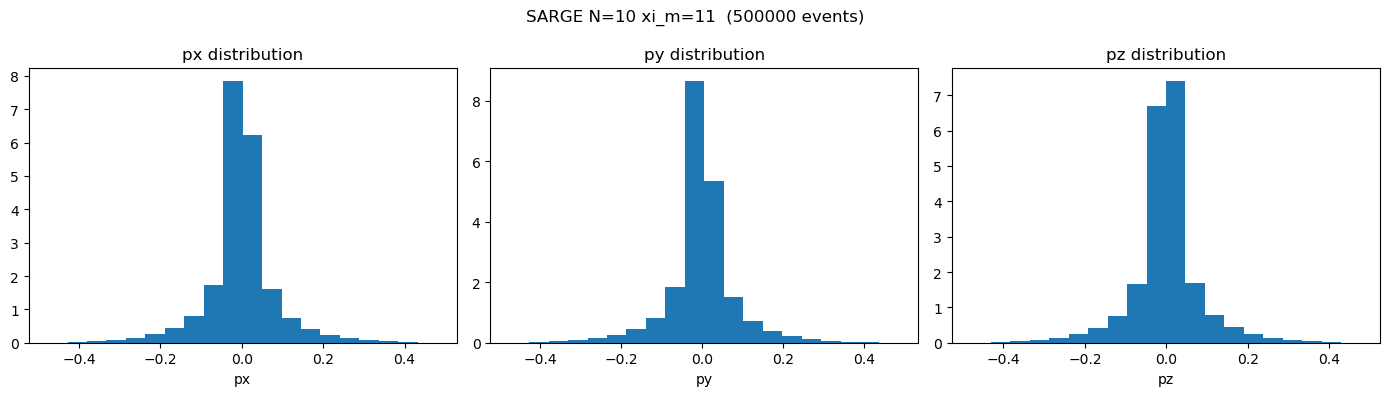

In [832]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Per-component distributions
labels = ['px', 'py', 'pz']
p_np = ev.numpy().reshape(-1, 3)
for i, ax in enumerate(axes):
    ax.hist(p_np[:, i], bins=20, density=True)
    ax.set_xlabel(labels[i])
    ax.set_title(f'{labels[i]} distribution')

plt.suptitle(f'SARGE N={N_PARTICLES} xi_m={XI_M}  ({N_EVENTS} events)')
plt.tight_layout()
plt.savefig('SARGE_momentum_distributions.png', dpi=150)
plt.show()

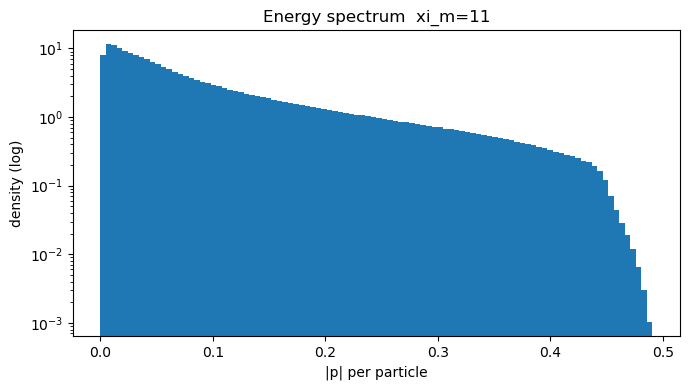

In [834]:
# Per-particle energy spectrum (log scale to see soft divergence)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(E_per_particle, bins=100, density=True, log=True)
ax.set_xlabel('|p| per particle')
ax.set_ylabel('density (log)')
ax.set_title(f'Energy spectrum  xi_m={XI_M}')
plt.tight_layout()
plt.savefig('SARGE_energy_spectrum.png', dpi=150)
plt.show()

## Save output

In [912]:
torch.save(q_events, OUTPUT_PATH_q)
#torch.save(p_events, OUTPUT_PATH_p)
#print(f'Saved {q_events.shape} tensor to {OUTPUT_PATH}')

In [ ]:
norms = q_events.norm(dim=2)                        # (N, 10)
print(f'Sum |q| per event : {norms.sum(dim=1)[:5]}')
print(f'Sum q per event :    {Q0_full.sum(dim=1)[:3]}')

In [762]:
def compute_tau(P):
    """
    P: (N_events, N_particles, 3)
       spatial momenta (px, py, pz)

    Returns:
        tau: (N_events,)
    """

    # Particle energies, assuming massless particles
    E = torch.linalg.norm(P, dim=-1)

    # Lorentz dot products
    # E_i E_j
    EE = E[:, :, None] * E[:, None, :]

    # p_i . p_j (Euclidean spatial dot product)
    pp = torch.einsum("bid,bjd->bij", P, P)

    # Minkowski dot product
    dots = EE - pp

    # Remove i=j
    n = P.shape[1]
    diagonal = torch.eye(
        n,
        dtype=torch.bool,
        device=P.device
    )

    dots = dots.masked_fill(diagonal[None, :, :], float("inf"))

    # Minimum i != j
    tau = dots.min(dim=2).values.min(dim=1).values

    return tau

    return tau

In [768]:
q_events,p_events = myQCD_antenna(100000, 20, xi_m=1.4, energy=1.0)

q_events1,p_events1 = myQCD_antenna(1000000, 20, xi_m=1.4, energy=1.0)

nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

tau_100K = compute_tau(p_events)

tau_100K = torch.log10(tau_100K[tau_100K >0])

tau_1000K = compute_tau(p_events1)

tau_1000K = torch.log10(tau_1000K[tau_1000K >0])


torch.Size([100000, 3])
torch.Size([100000])
torch.Size([1000000, 3])
torch.Size([1000000])
Generation took 4.20s
Shape: torch.Size([100000, 20, 3])
Shape: torch.Size([100000, 20, 3])
NaN events: 0  |  Inf events: 0
Value range: [-199.5091, 210.3330]
Value range: [-0.2364, 0.2308]


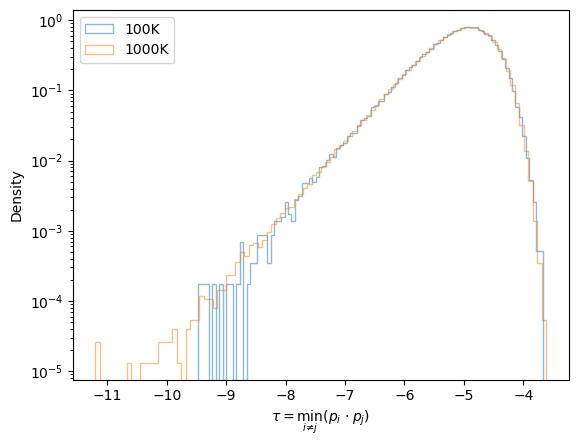

In [769]:
plt.hist(
    tau_100K.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="100K",
)

plt.hist(
    tau_1000K.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="1000K",
)
plt.yscale("log")

plt.xlabel(r"$\tau = \min_{i\ne j}(p_i\cdot p_j)$")
plt.ylabel("Density")
plt.legend()
plt.show()

torch.Size([100000, 3])
torch.Size([100000])


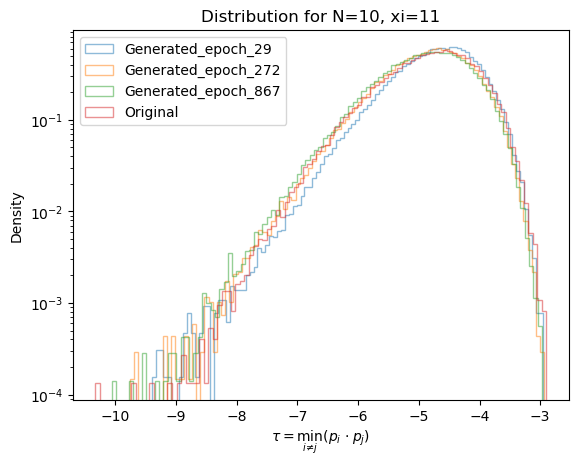

In [786]:
q_events,p_events = myQCD_antenna(100000, 10, xi_m=11, energy=1.0)

tau_100K = compute_tau(p_events)

tau_100K = torch.log10(tau_100K[tau_100K >0])


gen_events=torch.load("generated_dsm_eps_N10_100000_xi11_epoch=29.pt",weights_only=True)

tau_gen = compute_tau(gen_events)

tau_gen = torch.log10(tau_gen[tau_gen >0])

gen_events1=torch.load("generated_dsm_eps_N10_100000_xi11_epoch=272.pt",weights_only=True)

tau_gen1 = compute_tau(gen_events1)

tau_gen1 = torch.log10(tau_gen1[tau_gen1 >0])

gen_events2=torch.load("generated_dsm_eps_N10_100000_xi11_epoch=867.pt",weights_only=True)

tau_gen2 = compute_tau(gen_events2)

tau_gen2 = torch.log10(tau_gen2[tau_gen2 >0])

plt.hist(
    tau_gen.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_29",
)

plt.hist(
    tau_gen1.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_272",
)

plt.hist(
    tau_gen2.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_867",
)

plt.hist(
    tau_100K.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Original",
)

plt.yscale("log")

plt.xlabel(r"$\tau = \min_{i\ne j}(p_i\cdot p_j)$")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution for N=10, xi=11")
plt.savefig("N=10_xi=11.png")
plt.show()


torch.Size([100000, 3])
torch.Size([100000])
Generation took 4.20s
Shape: torch.Size([100000, 20, 3])
Shape: torch.Size([100000, 20, 3])
NaN events: 0  |  Inf events: 0
Value range: [-209.4727, 211.4261]
Value range: [-0.2278, 0.2062]


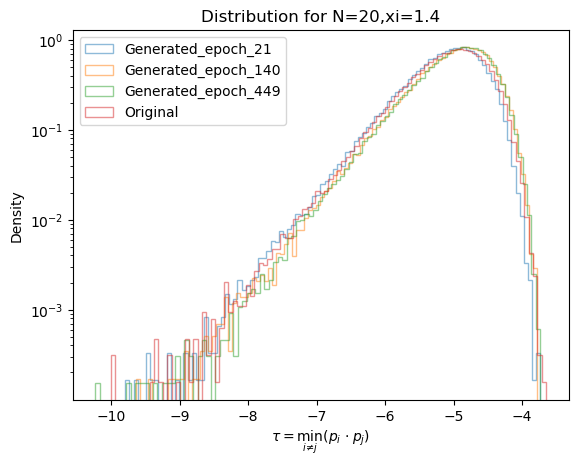

In [778]:
q_events,p_events = myQCD_antenna(100000, 20, xi_m=1.4, energy=1.0)


nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

tau_orig = compute_tau(p_events)

tau_orig = torch.log10(tau_orig[tau_orig >0])

gen_events=torch.load("generated_dsm_eps_N20_100000_xi1.4_epoch=21.pt",weights_only=True)

tau_gen = compute_tau(gen_events)

tau_gen = torch.log10(tau_gen[tau_gen >0])

gen_events1=torch.load("generated_dsm_eps_N20_100000_xi1.4_epoch=140.pt",weights_only=True)

tau_gen1 = compute_tau(gen_events1)

tau_gen1 = torch.log10(tau_gen1[tau_gen1 >0])

gen_events2=torch.load("generated_dsm_eps_N20_100000_xi1.4_epoch=449.pt",weights_only=True)

tau_gen2 = compute_tau(gen_events2)

tau_gen2 = torch.log10(tau_gen2[tau_gen2 >0])

plt.hist(
    tau_gen.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_21",
)

plt.hist(
    tau_gen1.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_140",
)

plt.hist(
    tau_gen2.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_449",
)

plt.hist(
    tau_orig.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Original",
)

plt.yscale("log")

plt.xlabel(r"$\tau = \min_{i\ne j}(p_i\cdot p_j)$")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution for N=20,xi=1.4")
plt.savefig("N=20.png")
plt.show()


torch.Size([100000, 3])
torch.Size([100000])
Generation took 4.20s
Shape: torch.Size([100000, 5, 3])
Shape: torch.Size([100000, 5, 3])
NaN events: 0  |  Inf events: 0
Value range: [-238532.5457, 299780.1504]
Value range: [-0.4998, 0.4990]


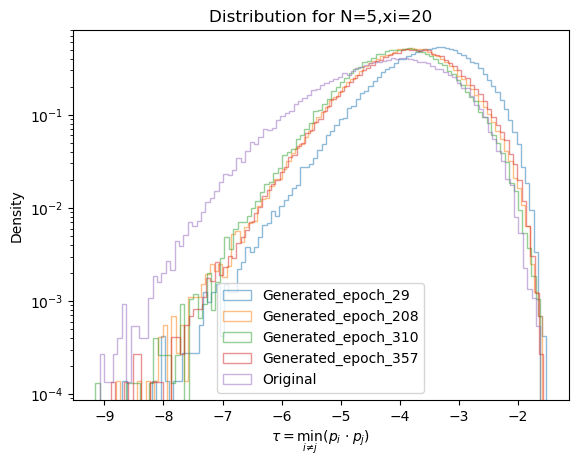

In [792]:
q_events,p_events = myQCD_antenna(100000, 5, xi_m=88, energy=1.0)


nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

tau_orig = compute_tau(p_events)

tau_orig = torch.log10(tau_orig[tau_orig >0])

gen_events=torch.load("generated_dsm_eps_N5_100000_xi88_epoch=29.pt",weights_only=True)

tau_gen = compute_tau(gen_events)

tau_gen = torch.log10(tau_gen[tau_gen >0])

gen_events1=torch.load("generated_dsm_eps_N5_100000_xi88_epoch=208.pt",weights_only=True)

tau_gen1 = compute_tau(gen_events1)

tau_gen1 = torch.log10(tau_gen1[tau_gen1 >0])

gen_events2=torch.load("generated_dsm_eps_N5_100000_xi88_epoch=310.pt",weights_only=True)

tau_gen2 = compute_tau(gen_events2)

tau_gen2 = torch.log10(tau_gen2[tau_gen2 >0])


gen_events3=torch.load("generated_dsm_eps_N5_100000_xi88_epoch=357.pt",weights_only=True)

tau_gen3 = compute_tau(gen_events3)

tau_gen3 = torch.log10(tau_gen3[tau_gen3 >0])


plt.hist(
    tau_gen.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_29",
)

plt.hist(
    tau_gen1.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_208",
)

plt.hist(
    tau_gen2.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_310",
)

plt.hist(
    tau_gen3.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Generated_epoch_357",
)


plt.hist(
    tau_orig.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="Original",
)

plt.yscale("log")

plt.xlabel(r"$\tau = \min_{i\ne j}(p_i\cdot p_j)$")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution for N=5,xi=20")
plt.savefig("N=5_xi=88.png")
plt.show()

torch.Size([2000000, 3])
torch.Size([2000000])
Generation took 4.20s
Shape: torch.Size([2000000, 5, 3])
Shape: torch.Size([2000000, 5, 3])
NaN events: 0  |  Inf events: 0
Value range: [-469020.7908, 379648.4502]
Value range: [-0.4998, 0.4998]
torch.Size([2000000, 3])
torch.Size([2000000])
Generation took 4.20s
Shape: torch.Size([2000000, 10, 3])
Shape: torch.Size([2000000, 10, 3])
NaN events: 0  |  Inf events: 0
Value range: [-8501327.9733, 15045358.8532]
Value range: [-0.4878, 0.4853]
torch.Size([2000000, 3])
torch.Size([2000000])
Generation took 4.20s
Shape: torch.Size([2000000, 20, 3])
Shape: torch.Size([2000000, 20, 3])
NaN events: 0  |  Inf events: 0
Value range: [-324.7711, 309.2079]
Value range: [-0.2375, 0.2496]


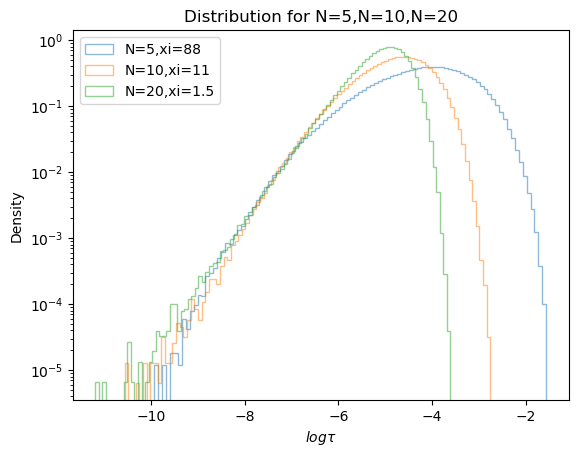

In [760]:
q_events,p_events = myQCD_antenna(2000000, 5, xi_m=88, energy=1.0)

nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

torch.save(p_events, "pSARGE_N5_xi_88_200k.pt")

tau_orig = compute_tau(p_events)

tau_N5 = torch.log10(tau_orig[tau_orig >0])



q_events,p_events = myQCD_antenna(2000000, 10, xi_m=11, energy=1.0)


nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

torch.save(p_events, "pSARGE_N10_xi_11_200k.pt")

tau_orig = compute_tau(p_events)

tau_N10 = torch.log10(tau_orig[tau_orig >0])



q_events,p_events = myQCD_antenna(2000000, 20, xi_m=1.4, energy=1.0)


nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

torch.save(p_events, "pSARGE_N20_xi_1.4_200k.pt")

tau_orig = compute_tau(p_events)

tau_N25 = torch.log10(tau_orig[tau_orig >0])

plt.hist(
    tau_N5.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="N=5,xi=88",
)

plt.hist(
    tau_N10.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="N=10,xi=11",
)

plt.hist(
    tau_N25.cpu().numpy(),
    bins=100,
    density=True,
    alpha=0.5,
    histtype="step",
    label="N=20,xi=1.5",
)

plt.yscale("log")

plt.xlabel(r"$log\tau $")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution for N=5,N=10,N=20")
plt.savefig("Distributions.png")
plt.show()

torch.Size([500000, 3])
torch.Size([500000])
Generation took 1.19s
Shape: torch.Size([500000, 5, 3])
Shape: torch.Size([500000, 5, 3])
NaN events: 0  |  Inf events: 0
Value range: [-14.6118, 14.3585]
Value range: [-0.4082, 0.4127]
Sum p per event :    tensor([[ 7.4506e-09,  0.0000e+00, -7.4506e-09],
        [-7.4506e-09,  0.0000e+00,  0.0000e+00],
        [-7.4506e-09, -1.7229e-08,  7.4506e-09]])
Momentum conservation  max|sum(p)|: 5.96e-08  (should be ~0)
Energy conservation    sum(|p|) mean: 1.000000  std: 2.81e-08  (should be 1.0)
Per-particle |p|: mean=0.2000  std=0.0709  max=0.4170
Fraction soft (|p|<0.01): 0.0000


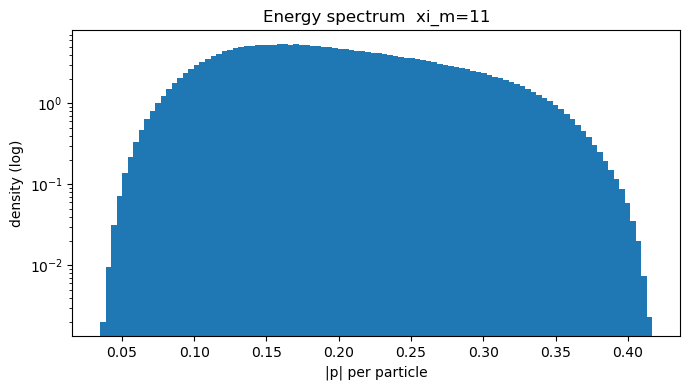

In [886]:
q_events,p_events = myQCD_antenna(500000, 5 , xi_m= 0.5, energy=1.0)

nan_ct = torch.isnan(p_events).any(-1).any(-1).sum().item()
inf_ct = torch.isinf(p_events).any(-1).any(-1).sum().item()

print(f'Generation took {dt:.2f}s')
print(f'Shape: {q_events.shape}')
print(f'Shape: {p_events.shape}')
print(f'NaN events: {nan_ct}  |  Inf events: {inf_ct}')
print(f'Value range: [{q_events.min():.4f}, {q_events.max():.4f}]')
print(f'Value range: [{p_events.min():.4f}, {p_events.max():.4f}]')

torch.save(p_events, "pSARGE_N5_xi_0.5_2000k.pt")

import numpy as np
import matplotlib.pyplot as plt

ev = p_events.float()

print(f'Sum p per event :    {ev.sum(dim=1)[:3]}')

# Momentum conservation: sum(p) per event should be ~0
mom_sum = ev.sum(dim=1)  # (N, 3)
print(f'Momentum conservation  max|sum(p)|: {mom_sum.abs().max():.2e}  (should be ~0)')

# Energy conservation: sum(|p|) = E_cm
E_per_event = torch.linalg.norm(ev, dim=2).sum(dim=1)  # (N,)
print(f'Energy conservation    sum(|p|) mean: {E_per_event.mean():.6f}  std: {E_per_event.std():.2e}  (should be {ENERGY})')

# Per-particle energy distribution
E_per_particle = torch.linalg.norm(ev, dim=2).flatten().numpy()  # (N*nparticles,)
print(f'Per-particle |p|: mean={E_per_particle.mean():.4f}  std={E_per_particle.std():.4f}  max={E_per_particle.max():.4f}')
print(f'Fraction soft (|p|<0.01): {(E_per_particle < 0.01).mean():.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(E_per_particle, bins=100, density=True, log=True)
ax.set_xlabel('|p| per particle')
ax.set_ylabel('density (log)')
ax.set_title(f'Energy spectrum  xi_m={XI_M}')
plt.tight_layout()
plt.savefig('SARGE_energy_spectrum.png', dpi=150)
plt.show()